**Set environment**

In [1]:
suppressMessages(suppressWarnings(source("../run_config_project_sing.R")))
library(gghalves)
show_env()

You are working on        Singularity: singularity_proj_encode_fcc 
BASE DIRECTORY (FD_BASE): /data/reddylab/Kuei 
REPO DIRECTORY (FD_REPO): /data/reddylab/Kuei/repo 
WORK DIRECTORY (FD_WORK): /data/reddylab/Kuei/work 
DATA DIRECTORY (FD_DATA): /data/reddylab/Kuei/data 

You are working with      ENCODE FCC 
PATH OF PROJECT (FD_PRJ): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC 
PROJECT RESULTS (FD_RES): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results 
PROJECT SCRIPTS (FD_EXE): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/scripts 
PROJECT DATA    (FD_DAT): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/data 
PROJECT NOTE    (FD_NBK): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/notebooks 
PROJECT DOCS    (FD_DOC): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/docs 
PROJECT LOG     (FD_LOG): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/log 
PROJECT REF     (FD_REF): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/references 



## Prepare

**Set global variable**

In [2]:
vec = c(
    "fcc_astarr_macs_input_overlap",
    "fcc_astarr_macs_input_union"
)
names(vec) = vec

VEC_TXT_FOLDER = vec
for(txt in vec){cat(txt, "\n")}

fcc_astarr_macs_input_overlap 
fcc_astarr_macs_input_union 


In [3]:
TXT_FNAME_ANNOT = "region.annotation.hic_intact_deep.loop.score.edge.tsv"

**View files**

In [1]:
txt_fdiry = file.path(FD_RES, "region_annotation", "*", "summary")
txt_fname = "region.annotation.hic_intact_deep.loop.score.edge.tsv"
txt_fglob = file.path(txt_fdiry, txt_fname)

vec = Sys.glob(txt_fglob)
for(txt in vec){cat(txt, "\n")}

ERROR: Error: object 'FD_RES' not found


## Import data

### Import region annotation

In [5]:
### loop to import data
lst = lapply(VEC_TXT_FOLDER, function(txt_folder){
    ### set file directory
    txt_fdiry = file.path(FD_RES, "region_annotation", txt_folder, "summary")
    txt_fname = TXT_FNAME_ANNOT
    txt_fpath = file.path(txt_fdiry, txt_fname)

    ### read table
    dat = read_tsv(txt_fpath, show_col_types = FALSE)
    return(dat)
})
names(lst) = VEC_TXT_FOLDER

### assign and show
lst_dat_region_annot_hic_import = lst

res = lapply(lst, dim)
print(res)

dat = lst[[1]]
fun_display_table(head(dat, 3))

$fcc_astarr_macs_input_overlap
[1] 111329     16

$fcc_astarr_macs_input_union
[1] 136954     16



Chrom_1,ChromStart_1,ChromEnd_1,Region_1,Chrom_2,ChromStart_2,ChromEnd_2,Region_2,Region_Edge,Loop_Count,Loop_Score_Mean,Loop_Score_Sum,Loop_Zcore_Global_Mean,Loop_Zcore_Global_Sum,Loop_Zcore_DistSm_Mean,Loop_Zcore_DistSm_Sum
chr1,778233,779389,chr1:778233-779389,chr1,826796,828040,chr1:826796-828040,chr1:778233-779389|chr1:826796-828040,1,1.947915,1.947915,0.3979698,0.3979698,0.5460845,0.5460845
chr1,869637,870233,chr1:869637-870233,chr1,935793,936234,chr1:935793-936234,chr1:869637-870233|chr1:935793-936234,1,1.128334,1.128334,-0.7931850,-0.7931850,-1.6579968,-1.6579968
chr1,869637,870233,chr1:869637-870233,chr1,975975,976656,chr1:975975-976656,chr1:869637-870233|chr1:975975-976656,1,1.771598,1.771598,0.1417154,0.1417154,-0.3986085,-0.3986085


In [6]:
### loop to import data
lst = lapply(VEC_TXT_FOLDER, function(txt_folder){
    ### set file directory
    txt_fdiry = file.path(FD_RES, "region_annotation", txt_folder, "summary")
    txt_fname = "region.annotation.fcc_starrmpra_junke.group.label.tsv"
    txt_fpath = file.path(txt_fdiry, txt_fname)

    ### read table
    dat = read_tsv(txt_fpath, show_col_types = FALSE)
    return(dat)
})

### assign and show
lst_dat_region_annot_fcc_import = lst

res = lapply(lst, dim)
print(res)

dat = lst[[1]]
fun_display_table(head(dat, 3))

$fcc_astarr_macs_input_overlap
[1] 150047      9

$fcc_astarr_macs_input_union
[1] 246862      9



Chrom,ChromStart,ChromEnd,Region,Distance2TSS,TSS_Proximity,TSS,Direction_Assay,Group
chr1,10038,10405,chr1:10038-10405,1469,Proximal,0,Inactive,Proximal:Inactive
chr1,14282,14614,chr1:14282-14614,2409,Distal,0,Inactive,Distal:Inactive
chr1,16025,16338,chr1:16025-16338,1099,Proximal,0,Inactive,Proximal:Inactive


In [7]:
setNames(1:3, letters[1:3])

a b c 
1 2 3

In [8]:
### loop to import data
lst = lapply(VEC_TXT_FOLDER, function(txt_folder){
    
    dat_region_annot_hic = lst_dat_region_annot_hic_import[[txt_folder]]
    dat_region_annot_fcc = lst_dat_region_annot_fcc_import[[txt_folder]]

    vec_txt_cname1 = c("Chrom", "ChromStart", "ChromEnd", "Region", "Group", "TSS_Proximity", "Direction_Assay")
    vec_txt_cname2 = paste(vec_txt_cname1, "1", sep = "_")
    vec_txt_lookup = setNames(vec_txt_cname1, vec_txt_cname2)
    tmp = dat_region_annot_fcc
    tmp = tmp %>% 
        dplyr::select(all_of(vec_txt_cname1)) %>%
        dplyr::rename(all_of(vec_txt_lookup))
    
    ### 
    dat = dat_region_annot_hic
    dat = dplyr::inner_join(dat, tmp, by = vec_txt_cname2[1:4], relationship = "many-to-many")

    ###
    vec_txt_cname1 = c("Chrom", "ChromStart", "ChromEnd", "Region", "Group", "TSS_Proximity", "Direction_Assay")
    vec_txt_cname2 = paste(vec_txt_cname1, "2", sep = "_")
    vec_txt_lookup = setNames(vec_txt_cname1, vec_txt_cname2)
    tmp = dat_region_annot_fcc
    tmp = tmp %>% 
        dplyr::select(all_of(vec_txt_cname1)) %>%
        dplyr::rename(all_of(vec_txt_lookup))
    
    ### 
    dat = dplyr::inner_join(dat, tmp, by = vec_txt_cname2[1:4], relationship = "many-to-many")
    return(dat)
})

### assign and show
lst_dat_region_annot_merge = lst

res = lapply(lst, dim)
print(res)

dat = lst[[1]]
fun_display_table(head(dat, 3))

$fcc_astarr_macs_input_overlap
[1] 111333     22

$fcc_astarr_macs_input_union
[1] 136958     22



Chrom_1,ChromStart_1,ChromEnd_1,Region_1,Chrom_2,ChromStart_2,ChromEnd_2,Region_2,Region_Edge,Loop_Count,Loop_Score_Mean,Loop_Score_Sum,Loop_Zcore_Global_Mean,Loop_Zcore_Global_Sum,Loop_Zcore_DistSm_Mean,Loop_Zcore_DistSm_Sum,Group_1,TSS_Proximity_1,Direction_Assay_1,Group_2,TSS_Proximity_2,Direction_Assay_2
chr1,778233,779389,chr1:778233-779389,chr1,826796,828040,chr1:826796-828040,chr1:778233-779389|chr1:826796-828040,1,1.947915,1.947915,0.3979698,0.3979698,0.5460845,0.5460845,Proximal:Active,Proximal,Active,Proximal:Inactive,Proximal,Inactive
chr1,869637,870233,chr1:869637-870233,chr1,935793,936234,chr1:935793-936234,chr1:869637-870233|chr1:935793-936234,1,1.128334,1.128334,-0.7931850,-0.7931850,-1.6579968,-1.6579968,Distal:Inactive,Distal,Inactive,Distal:Inactive,Distal,Inactive
chr1,869637,870233,chr1:869637-870233,chr1,975975,976656,chr1:975975-976656,chr1:869637-870233|chr1:975975-976656,1,1.771598,1.771598,0.1417154,0.1417154,-0.3986085,-0.3986085,Distal:Inactive,Distal,Inactive,Distal:Inactive,Distal,Inactive


In [9]:
lst = lst_dat_region_annot_merge
lst = lapply(lst, function(dat){
    dat = dat %>% 
        dplyr::rowwise() %>%
        dplyr::mutate(
            Edge_Group = paste(sort(c(TSS_Proximity_1,   TSS_Proximity_2)),   collapse = "-"),
            Edge_Label = paste(sort(c(Direction_Assay_1, Direction_Assay_2)), collapse = "-")
        ) %>%
        dplyr::ungroup()

    return(dat)
})

###
lst_dat_region_annot_label = lst
res = lapply(lst, dim)
print(res)

dat = lst[[1]]
fun_display_table(head(dat, 3))

$fcc_astarr_macs_input_overlap
[1] 111333     24

$fcc_astarr_macs_input_union
[1] 136958     24



Chrom_1,ChromStart_1,ChromEnd_1,Region_1,Chrom_2,ChromStart_2,ChromEnd_2,Region_2,Region_Edge,Loop_Count,Loop_Score_Mean,Loop_Score_Sum,Loop_Zcore_Global_Mean,Loop_Zcore_Global_Sum,Loop_Zcore_DistSm_Mean,Loop_Zcore_DistSm_Sum,Group_1,TSS_Proximity_1,Direction_Assay_1,Group_2,TSS_Proximity_2,Direction_Assay_2,Edge_Group,Edge_Label
chr1,778233,779389,chr1:778233-779389,chr1,826796,828040,chr1:826796-828040,chr1:778233-779389|chr1:826796-828040,1,1.947915,1.947915,0.3979698,0.3979698,0.5460845,0.5460845,Proximal:Active,Proximal,Active,Proximal:Inactive,Proximal,Inactive,Proximal-Proximal,Active-Inactive
chr1,869637,870233,chr1:869637-870233,chr1,935793,936234,chr1:935793-936234,chr1:869637-870233|chr1:935793-936234,1,1.128334,1.128334,-0.7931850,-0.7931850,-1.6579968,-1.6579968,Distal:Inactive,Distal,Inactive,Distal:Inactive,Distal,Inactive,Distal-Distal,Inactive-Inactive
chr1,869637,870233,chr1:869637-870233,chr1,975975,976656,chr1:975975-976656,chr1:869637-870233|chr1:975975-976656,1,1.771598,1.771598,0.1417154,0.1417154,-0.3986085,-0.3986085,Distal:Inactive,Distal,Inactive,Distal:Inactive,Distal,Inactive,Distal-Distal,Inactive-Inactive


In [10]:
lst = lst_dat_region_annot_label
dat = lst[[1]]
table(dat$Edge_Group, dat$Edge_Label)

                   
                    Active-Active Active-Inactive Active-Repressive
  Distal-Distal              1723           11335               150
  Distal-Proximal            3816           15875               222
  Proximal-Proximal          4960            8482               148
                   
                    Inactive-Inactive Inactive-Repressive Repressive-Repressive
  Distal-Distal                 41251                1111                     9
  Distal-Proximal               17445                 613                     5
  Proximal-Proximal              4040                 148                     0

In [11]:
### set text size
theme_text = theme(
    title      = element_text(size = 16),
    axis.title = element_text(size = 16),
    axis.text  = element_text(size = 16),
    strip.text.x = element_text(size = 16)
)

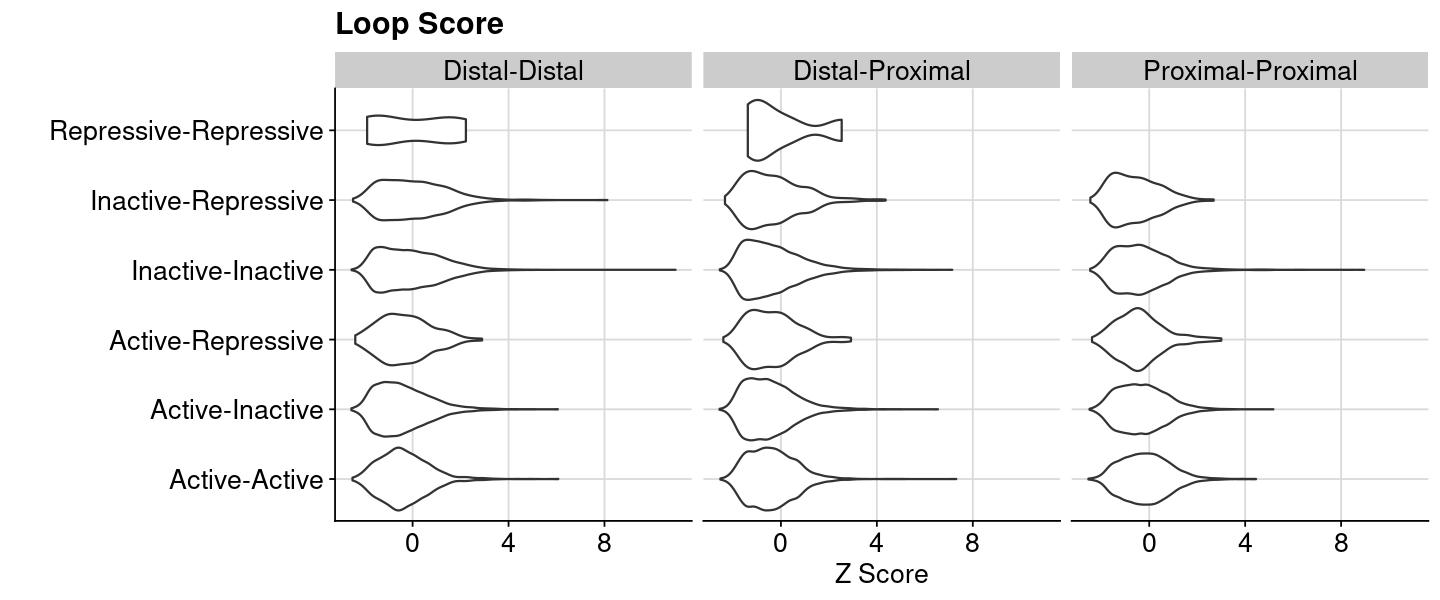

In [12]:
lst = lst_dat_region_annot_label
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore_DistSm_Sum, y=Edge_Label)) +
        geom_violin() +
        theme_cowplot() +
        background_grid() +
        labs(title = "Loop Score", x = "Z Score", y = "") +
        facet_wrap(~Edge_Group) +
        theme_text
    return(gpt)
})

gpt = lst[[1]]

options(repr.plot.height=5, repr.plot.width=12)
print(gpt)

In [14]:
idx_region = "fcc_astarr_macs_input_overlap"

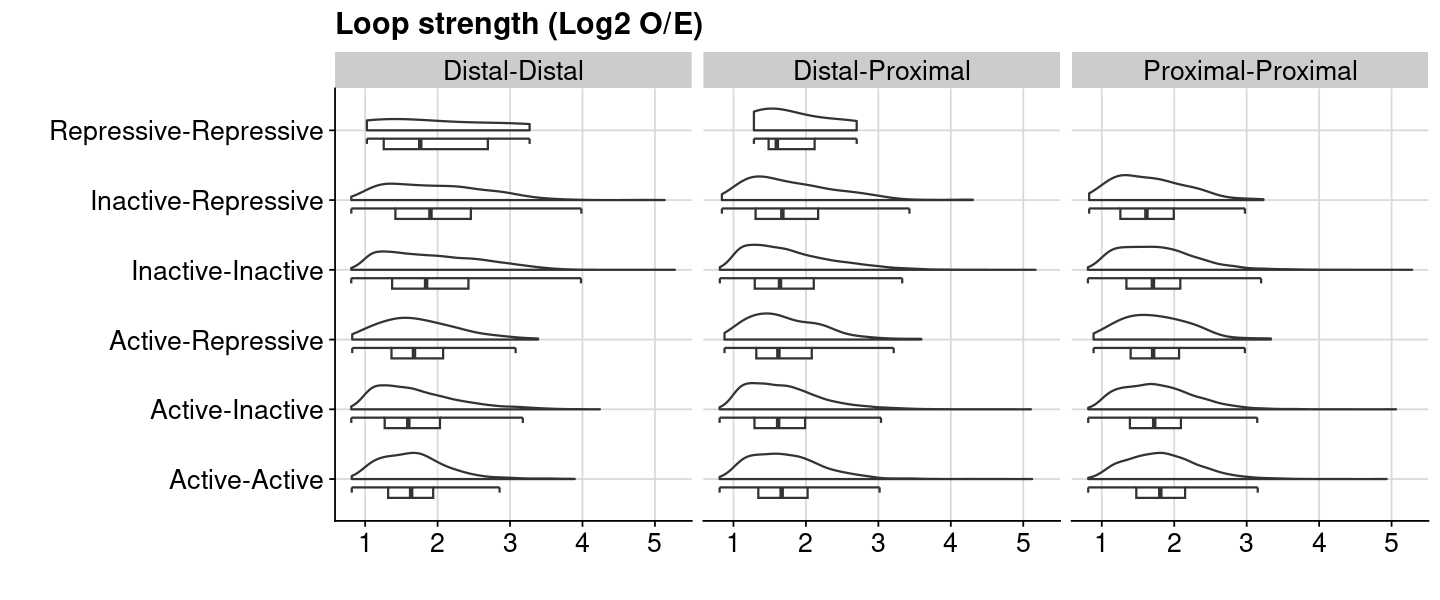

In [24]:
lst = lst_dat_region_annot_label
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Edge_Label, y=Loop_Score_Sum)) +
        geom_half_violin(side = "r", trim = TRUE, alpha = 0.4, adjust = 1.2) +
        geom_half_boxplot(side = "l", width = 0.3, position = position_nudge(x = -0.12), outlier.shape = NA) +
        theme_cowplot() +
        background_grid() +
        labs(title = "Loop strength (Log2 O/E)", x = "", y = "") +
        facet_wrap(~Edge_Group) +
        theme_text +
        coord_flip()
    return(gpt)
})

gpt = lst[[idx_region]]
gpt_export_loop_score = gpt
options(repr.plot.height=5, repr.plot.width=12)
print(gpt)

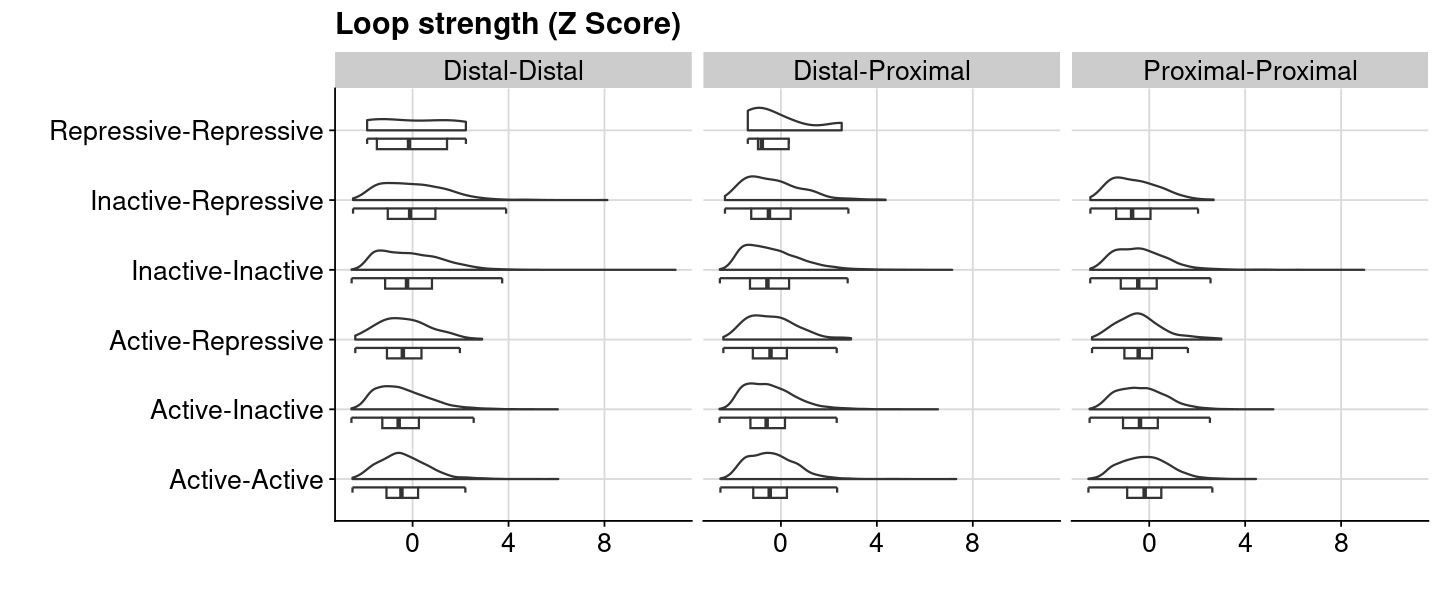

In [25]:
lst = lst_dat_region_annot_label
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Edge_Label, y=Loop_Zcore_DistSm_Sum)) +
        geom_half_violin(side = "r", trim = TRUE, alpha = 0.4, adjust = 1.2) +
        geom_half_boxplot(side = "l", width = 0.3, position = position_nudge(x = -0.12), outlier.shape = NA) +
        theme_cowplot() +
        background_grid() +
        labs(title = "Loop strength (Z Score)", x = "", y = "") +
        facet_wrap(~Edge_Group) +
        theme_text +
        coord_flip()
    return(gpt)
})

gpt = lst[[idx_region]]
gpt_export_loop_score = gpt
options(repr.plot.height=5, repr.plot.width=12)
print(gpt)

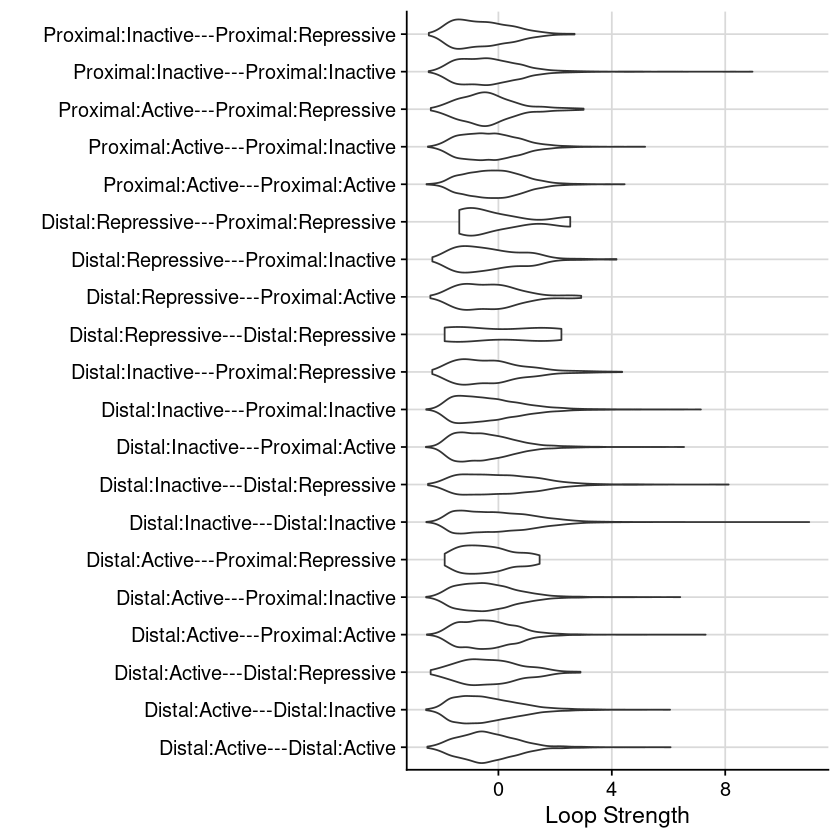

In [13]:
lst = lst_dat_region_annot_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore_DistSm_Sum, y=Label)) +
        geom_violin() +
        theme_cowplot() +
        background_grid() +
        labs(x = "Loop Strength", y = "")
    return(gpt)
})

gpt = lst[[1]]

options(repr.plot.height=7, repr.plot.width=7)
print(gpt)